In [1]:
!pip install -q transformers datasets accelerate evaluate scikit-learn pandas torch

import torch
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from datasets import Dataset, DatasetDict
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding
)
import evaluate
# Set device to T4 GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device} ({torch.cuda.get_device_name(0)})")


Using device: cuda (Tesla T4)


In [2]:
import pandas as pd
import numpy as np
import torch

from sklearn.model_selection import train_test_split
from datasets import Dataset, DatasetDict

df = pd.read_csv("/content/hindi_humour.csv")

df = df.dropna(subset=["text", "label"]).copy()
df["text"] = df["text"].astype(str).str.strip()
df = df[df["text"] != ""]

# Remove exact duplicate text-label pairs
df = df.drop_duplicates(subset=["text", "label"])

# Remove ambiguous texts with conflicting labels
conflicts = df.groupby("text")["label"].nunique()
conflicting_texts = conflicts[conflicts > 1].index

df = df[~df["text"].isin(conflicting_texts)].copy()

df["label"] = df["label"].astype(int)

print("Clean dataset:", len(df))
print(df["label"].value_counts())

train_df, temp_df = train_test_split(
    df,
    test_size=0.2,
    stratify=df["label"],
    random_state=42
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.5,
    stratify=temp_df["label"],
    random_state=42
)

dataset = DatasetDict({
    "train": Dataset.from_pandas(
        train_df[["text", "label"]].reset_index(drop=True)
    ),
    "validation": Dataset.from_pandas(
        val_df[["text", "label"]].reset_index(drop=True)
    ),
    "test": Dataset.from_pandas(
        test_df[["text", "label"]].reset_index(drop=True)
    )
})

Clean dataset: 11675
label
0    7887
1    3788
Name: count, dtype: int64


In [4]:

print(dataset["train"].shape)
print(dataset["validation"].shape)
print(dataset["test"].shape)

(9340, 2)
(1167, 2)
(1168, 2)


In [5]:
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding
)

MODEL_CHECKPOINT = "xlm-roberta-base"

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_CHECKPOINT
)

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_CHECKPOINT,
    num_labels=2
)

encoded_dataset = dataset.map(
    lambda x: tokenizer(
        x["text"],
        truncation=True,
        max_length=128
    ),
    batched=True
)

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.dense.bias          | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.bias    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Map:   0%|          | 0/9340 [00:00<?, ? examples/s]

Map:   0%|          | 0/1167 [00:00<?, ? examples/s]

Map:   0%|          | 0/1168 [00:00<?, ? examples/s]

In [6]:
print(encoded_dataset["train"][0])

{'text': 'की तरह, तुम लोग सभी नौकरियों', 'label': 0, 'input_ids': [0, 471, 15107, 4, 36733, 19181, 17415, 56615, 3130, 7549, 2], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]}


In [7]:
from sklearn.utils.class_weight import compute_class_weight
from transformers import Trainer

classes = np.array([0, 1])

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_df["label"].values
)

class_weights = torch.tensor(
    weights,
    dtype=torch.float32
)

print("Class weights:", class_weights)

class WeightedTrainer(Trainer):

    def compute_loss(
        self,
        model,
        inputs,
        return_outputs=False,
        num_items_in_batch=None
    ):
        labels = inputs["labels"]

        outputs = model(**inputs)
        logits = outputs.logits

        loss_fn = torch.nn.CrossEntropyLoss(
            weight=class_weights.to(logits.device)
        )

        loss = loss_fn(
            logits,
            labels
        )

        return (loss, outputs) if return_outputs else loss

Class weights: tensor([0.7401, 1.5413])


In [8]:
import pandas as pd
import numpy as np
from transformers import AutoTokenizer
from sklearn.model_selection import train_test_split

# 1. Load your dataset
df = pd.read_csv("/content/hindi_humour.csv")
df = df.dropna(subset=["text", "label"]).copy()
df["text"] = df["text"].astype(str)

# 2. Load the same tokenizer as your project
MODEL_CHECKPOINT = "xlm-roberta-base"
MAX_LENGTH = 128

tokenizer = AutoTokenizer.from_pretrained(MODEL_CHECKPOINT)
# 3. Calculate token lengths WITHOUT truncation
texts = df["text"].tolist()
token_lengths = []

for start in range(0, len(texts), 256):
    batch = texts[start:start + 256]

    encoded = tokenizer(
        batch,
        truncation=False,
        add_special_tokens=True
    )

    token_lengths.extend(
        [len(ids) for ids in encoded["input_ids"]]
    )

df["token_length"] = token_lengths

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (561 > 512). Running this sequence through the model will result in indexing errors


In [9]:
# 4. Calculate truncation statistics
df["will_truncate"] = df["token_length"] > MAX_LENGTH

print("Total texts:", len(df))
print("Mean token length:", round(df["token_length"].mean(), 2))
print("Median token length:", df["token_length"].median())
print("95th percentile:", df["token_length"].quantile(0.95))
print("99th percentile:", df["token_length"].quantile(0.99))
print("Maximum token length:", df["token_length"].max())

truncated_count = int(df["will_truncate"].sum())
truncation_rate = df["will_truncate"].mean() * 100

print("\nTexts exceeding 128 tokens:", truncated_count)
print(f"Truncation rate: {truncation_rate:.2f}%")

# 5. Token-length distribution
bins = [0, 32, 64, 128, float("inf")]
labels = ["1–32", "33–64", "65–128", ">128"]

df["length_bucket"] = pd.cut(
    df["token_length"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

print("\nToken length distribution:")
print(df["length_bucket"].value_counts(sort=False))

# 6. Create the same 80/10/10 split
train_df, temp_df = train_test_split(
    df,
    test_size=0.2,
    random_state=42,
    stratify=df["label"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.5,
    random_state=42,
    stratify=temp_df["label"]
)



Total texts: 15562
Mean token length: 40.63
Median token length: 31.0
95th percentile: 107.0
99th percentile: 176.38999999999942
Maximum token length: 926

Texts exceeding 128 tokens: 436
Truncation rate: 2.80%

Token length distribution:
length_bucket
1–32      8142
33–64     4703
65–128    2281
>128       436
Name: count, dtype: int64


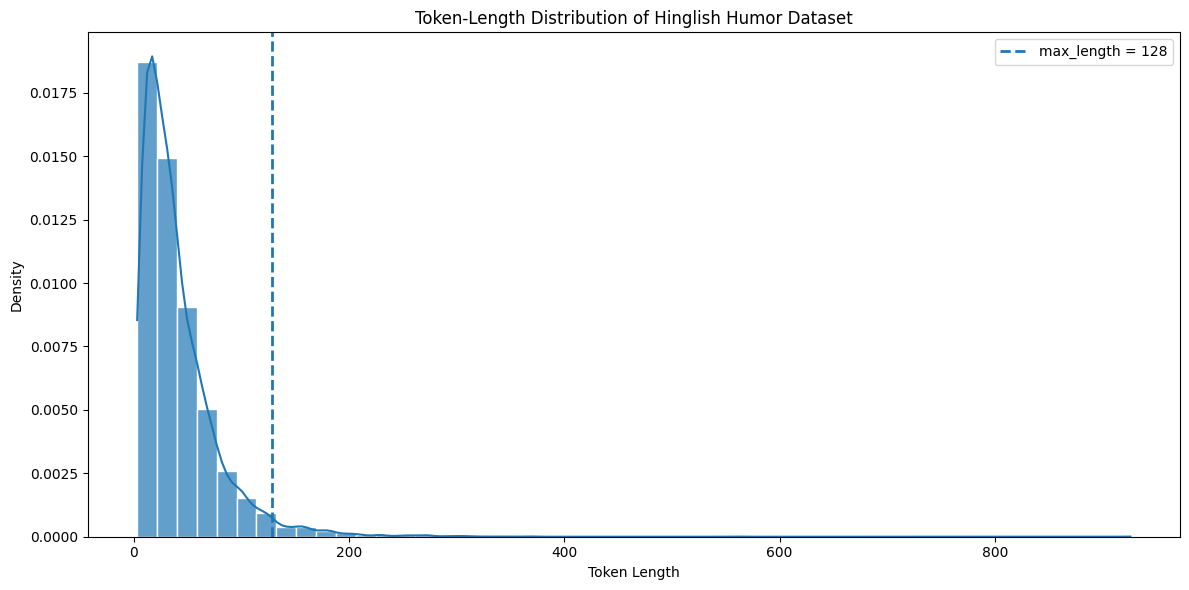

Total valid texts: 15562
Mean token length: 40.63
Median token length: 31.0
Texts exceeding 128 tokens: 436


In [10]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
df_plot = df.dropna(subset=["text"]).copy()
df_plot["token_length"] = df_plot["text"].astype(str).apply(
    lambda text: len(tokenizer.encode(text, add_special_tokens=True))
)

# Plot Histogram + KDE
plt.figure(figsize=(12, 6))

sns.histplot(
    data=df_plot,
    x="token_length",
    bins=50,
    kde=True,
    stat="density",
    edgecolor="white",
    alpha=0.7
)

plt.axvline(
    128,
    linestyle="--",
    linewidth=2,
    label="max_length = 128"
)

plt.title("Token-Length Distribution of Hinglish Humor Dataset")
plt.xlabel("Token Length")
plt.ylabel("Density")
plt.legend()
plt.tight_layout()
plt.show()

print("Total valid texts:", len(df_plot))
print("Mean token length:", round(df_plot["token_length"].mean(), 2))
print("Median token length:", df_plot["token_length"].median())
print(
    "Texts exceeding 128 tokens:",
    (df_plot["token_length"] > 128).sum()
)


In [11]:
import evaluate
import numpy as np

accuracy_metric = evaluate.load("accuracy")
f1_metric = evaluate.load("f1")

def compute_metrics(eval_pred):
    predictions, labels = eval_pred
    preds = np.argmax(predictions, axis=1)

    return {
        "accuracy": accuracy_metric.compute(
            predictions=preds,
            references=labels
        )["accuracy"],

        "f1": f1_metric.compute(
            predictions=preds,
            references=labels,
            average="weighted"
        )["f1"]
    }

In [12]:
from transformers import (
    TrainingArguments,
    EarlyStoppingCallback
)

training_args = TrainingArguments(
    output_dir="./improved_humour_model",

    eval_strategy="epoch",
    save_strategy="epoch",

    learning_rate=2e-5,

    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,

    num_train_epochs=4,
    weight_decay=0.01,
    # warmup_ratio=0.1,

    fp16=torch.cuda.is_available(),

    load_best_model_at_end=True,
    metric_for_best_model="f1",
    greater_is_better=True,

    save_total_limit=2,
    report_to="none",
    seed=42
)

trainer = WeightedTrainer(
    model=model,
    args=training_args,

    train_dataset=encoded_dataset["train"],
    eval_dataset=encoded_dataset["validation"],

    processing_class=tokenizer,

    data_collator=DataCollatorWithPadding(
        tokenizer=tokenizer
    ),

    compute_metrics=compute_metrics,

    callbacks=[]
)

trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.685950,0.641083,0.581834,0.589717
2,0.663304,0.635431,0.643530,0.652118
3,0.640848,0.621143,0.631534,0.642316
4,0.630100,0.621908,0.628963,0.640079


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=2336, training_loss=0.6505563357104994, metrics={'train_runtime': 807.2954, 'train_samples_per_second': 46.278, 'train_steps_per_second': 2.894, 'total_flos': 2092230334451040.0, 'train_loss': 0.6505563357104994, 'epoch': 4.0})

In [13]:
load_best_model_at_end=True,
metric_for_best_model="f1",
greater_is_better=True,

In [14]:
# 7. Train & Evaluate
trainer.train()
print("\nTest Evaluation Results:", trainer.evaluate(encoded_dataset["test"]))

Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.647970,0.642329,0.621251,0.633073
2,0.637874,0.646956,0.647815,0.657799
3,0.608623,0.631179,0.615253,0.625445
4,0.598637,0.638028,0.628106,0.639810


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,Accuracy,F1
0.598637,0.652087,4,0.640411,0.650805



Test Evaluation Results: {'eval_loss': 0.6520866751670837, 'eval_accuracy': 0.6404109589041096, 'eval_f1': 0.6508052084607138}


In [15]:
 # 8. Updated Quick Inference Function
def predict_humor_fixed(text_input):
    model.eval()
    inputs = tokenizer(text_input, return_tensors="pt", truncation=True, max_length=128).to(device)
    with torch.no_grad():
        outputs = model(**inputs)

    probs = torch.nn.functional.softmax(outputs.logits, dim=-1)
    pred_label = torch.argmax(probs, dim=-1).item()
    corrected_label = pred_label

    label_map = {0: "Non-Humorous", 1: "Humorous"}
    print(f"\nText: '{text_input}'")
    print(f"Prediction: {label_map[corrected_label]}")

# Test
predict_humor_fixed("Subah uthke coding karne ka sapna dekha tha, neend khuli toh pata chala deadline aaj hi hai! 😂")


Text: 'Subah uthke coding karne ka sapna dekha tha, neend khuli toh pata chala deadline aaj hi hai! 😂'
Prediction: Humorous


# testing 100 samples from the test data


In [16]:

import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Select 100 samples from the test dataset
test_data = encoded_dataset["test"]

n = min(100, len(test_data))
sample_data = test_data.shuffle(seed=42).select(range(n))

# 2. Generate predictions using your trained model
pred_output = trainer.predict(sample_data)

# 3. Get predicted and actual labels
y_pred = np.argmax(pred_output.predictions, axis=1)
y_true = np.array(pred_output.label_ids)

# 4. Calculate accuracy
accuracy = accuracy_score(y_true, y_pred)

print(f"Number of test samples: {n}")
print(f"Correct predictions: {(y_true == y_pred).sum()}")
print(f"Incorrect predictions: {(y_true != y_pred).sum()}")
print(f"Accuracy: {accuracy * 100:.2f}%")

# 5. Detailed performance report
print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=["Non-Humorous", "Humorous"],
    zero_division=0
))

# 6. Display actual vs predicted results
label_map = {
    0: "Non-Humorous",
    1: "Humorous"
}

results_df = pd.DataFrame({
    "Text": sample_data["text"],
    "Actual Label": [label_map[int(x)] for x in y_true],
    "Predicted Label": [label_map[int(x)] for x in y_pred],
    "Correct": y_true == y_pred
})

display(results_df)


Number of test samples: 100
Correct predictions: 66
Incorrect predictions: 34
Accuracy: 66.00%

Classification Report:
              precision    recall  f1-score   support

Non-Humorous       0.88      0.61      0.72        71
    Humorous       0.45      0.79      0.57        29

    accuracy                           0.66       100
   macro avg       0.66      0.70      0.65       100
weighted avg       0.75      0.66      0.68       100



,Text,Actual Label,Predicted Label,Correct
0,madamaaye gadhee 17000 ke jarie vaama vrddhi k...,Humorous,Humorous,True
1,जाजिर्यस pyaara उस वक्त sachin मेरी तबीयत kr...,Non-Humorous,Non-Humorous,True
2,jara chhal jor se meet bolo laud sirf aiktin...,Non-Humorous,Non-Humorous,True
3,पता है कि? यह खत्म नहीं हुआ है। हम आपको फिर से...,Non-Humorous,Humorous,False
4,उन्हें के मा के पाठ्यक्रम एक। आपका क्या मामला,Humorous,Humorous,True
...,...,...,...,...
95,इंद्रवदन लीजिये कचरा बाहर हैं को 1,Non-Humorous,Humorous,False
96,"फ्रांसिस ji, वह कितने बेस्ट सारे संसार ailai...",Non-Humorous,Non-Humorous,True
97,kya idalee hua kya tumako magar mujhe क्यों ...,Non-Humorous,Non-Humorous,True
98,eksapreshan main ga भैंस lungi kisi hathaudon,Non-Humorous,Non-Humorous,True
